## **salary predction linear regression**

In [6]:
import pandas as pd

df = pd.read_csv("/content/Salary Data.csv")
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 324 entries, 0 to 371
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  324 non-null    float64
 1   Gender               324 non-null    object 
 2   Education Level      324 non-null    object 
 3   Job Title            324 non-null    object 
 4   Years of Experience  324 non-null    float64
 5   Salary               324 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [15]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [7]:
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [8]:
print("number of dublicated",df.duplicated().sum())

number of dublicated 49


In [9]:
df.drop_duplicates(inplace=True)

print("number of duplicated after dropping:", df.duplicated().sum())

number of duplicated after dropping: 0


## **importing**

In [12]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , mean_absolute_error , r2_score

## **to check outliers**

<Axes: ylabel='Years of Experience'>

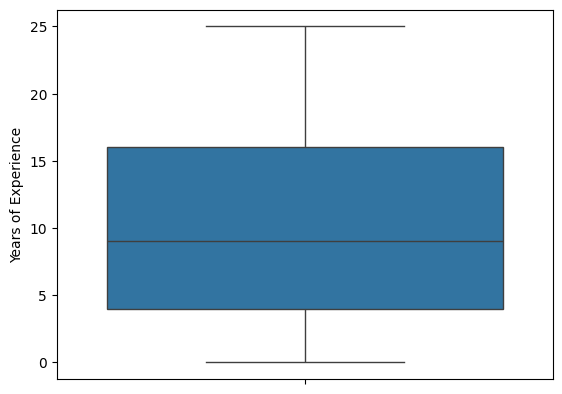

In [16]:
sns.boxplot(df["Years of Experience"])


<Axes: ylabel='Age'>

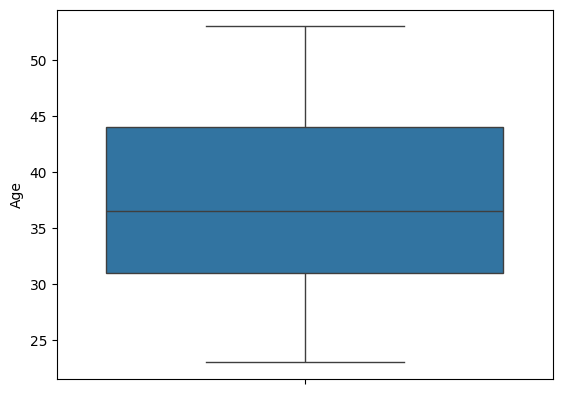

In [17]:
sns.boxplot(df["Age"])

## **Encoding**

In [18]:
GE = LabelEncoder()
df["Gender_encoded"] = GE.fit_transform(df["Gender"])
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1


In [21]:
EDU = LabelEncoder()
df["Education_encoded"] = EDU.fit_transform(df["Education Level"])
df.head(10)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Gender_encoded,Education_encoded
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,0,1
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,1,2
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,0,0
4,52.0,Male,Master's,Director,20.0,200000.0,1,1
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0,1,0
6,42.0,Female,Master's,Product Manager,12.0,120000.0,0,1
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0,1,0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0,0,0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0,1,2


## **Seprating dependent and independent variables**

In [24]:
X = df[["Age","Years of Experience","Gender_encoded","Education_encoded"]]
Y = df["Salary"]
print("feature shape:",x.shape,"Target shape:",y.shape)

feature shape: (324, 4) Target shape: (324,)


## **Split train and test**
**X_tain(300questions), X_test(200questions), Y_train(300 answers), Y_test(200 answers)**

In [28]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.20,random_state=42)

In [29]:
print("records for training:",len(X_train))
print("records for testing:",len(X_test))

records for training: 259
records for testing: 65


## **Scaling**

In [30]:
num_cols = ["Age","Years of Experience"]
my_scaler = StandardScaler()
X_train[num_cols] = my_scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = my_scaler.transform(X_test[num_cols])
print(X_train)

          Age  Years of Experience  Gender_encoded  Education_encoded
73  -1.324980            -1.226813               1                  0
182  0.877474             0.714752               0                  2
17   0.189207             0.266698               1                  2
24   0.464514             0.416049               1                  1
146  0.602167             0.864103               0                  2
..        ...                  ...             ...                ...
189 -1.324980            -1.301488               1                  0
71   0.189207             0.117347               0                  0
106 -1.049673            -1.077461               0                  0
284 -0.361406            -0.181355               1                  0
102  1.565740             1.312156               0                  1

[259 rows x 4 columns]


## **Train the model**

In [34]:
from sklearn.linear_model import LinearRegression
salary_model = LinearRegression()
salary_model.fit(X_train, Y_train)


LinearRegression()

# **Testing**

In [38]:
y_predict = salary_model.predict(X_test)

result = pd.DataFrame({
    "Actual": Y_test,
    "Predicted_by_model": y_predict
})

result.head(10)

,Actual,Predicted_by_model
132,100000.0,116136.607289
108,100000.0,124667.619930
137,50000.0,49205.367039
9,110000.0,127707.611369
181,105000.0,106510.651731
126,95000.0,99010.342045
221,45000.0,49269.607001
198,55000.0,57800.619642
279,180000.0,167515.403021
144,40000.0,43205.440089


## **predction by user input**

In [39]:
age = int(input("enter age:"))
years = int(input("enter the year of exp:"))
gen = input("enter the gender")
el = input("enter the education level:")

enter age:24
enter the year of exp:3
enter the gendermale
enter the education level:PhD


In [49]:
gen = GE.transform([gen.strip().capitalize()])[0]
el = EDU.transform([el.strip()])[0]

In [51]:
age, years = my_scaler.transform([[age,years]])[0]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [53]:
result = salary_model.predict([[age,years,gen,el]])
print("prdicted salary:",result)

prdicted salary: [67540.84315065]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
